# 5번 에이전트: 지배구조·경영진 분석 (삼성전자 예시)

- 작성일: 2026-10-27
- 대상: 삼성전자(005930, DART 고유번호 00126380)
- 목적: 대주주·경영진·이사회·주주환원·법적 리스크를 **근거 + 규칙**으로 판정하고, 오케스트레이터(6번)에 넘길 AgentMemo를 만든다.

## 팀 원칙과 이 노트북의 대응
| 팀 원칙 | 이 노트북에서 지키는 방식 |
| --- | --- |
| 숫자 생성 금지 | 모든 수치는 근거 표(evidence)에서만 가져온다. 계산은 pandas가 한다 |
| 출처 필수 | 근거마다 `evidence_id`, 출처 URL, 상태(보도·공시)를 붙인다 |
| 투자 권유 금지 | 판정은 "긍정·중립·주의·자료 없음" 신호만 쓴다 |

## 데이터 모드
- **DART 모드**: `.env`에 `DART_API_KEY`가 있으면 OpenDART 정기보고서 API를 조회한다.
- **보도 기준 모드**: 키가 없으면 언론 보도에서 정리한 근거 표를 쓴다. DART 원문 대조 전이므로 결과는 `partial`이다.

> 투자 권유가 아니다. 보도 기준 수치는 DART 원문으로 다시 확인해야 한다.

## 1. 환경 설정
수업 자료 `01_python/ch14`(requests·dotenv), `ch11`(pandas), `ch12`(matplotlib) 방식을 그대로 쓴다.

In [1]:
import os, json
import requests
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

plt.rcParams['font.family'] = 'Malgun Gothic'   # Windows 한글 글꼴
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_colwidth', 60)

load_dotenv()
DART_API_KEY = os.getenv('DART_API_KEY')
CORP_CODE = '00126380'      # 삼성전자 DART 고유번호
AS_OF = '2026-10-27'        # 분석 기준일: 이 날짜 이후 정보는 쓰지 않는다
MODE = 'DART' if DART_API_KEY else '보도 기준'
print('데이터 모드:', MODE)

데이터 모드: DART


## 2. DART 수집 함수 (키가 있을 때만 실행)
OpenDART 정기보고서 주요정보 API다. `reprt_code`는 11011 사업보고서, 11012 반기, 11013 1분기, 11014 3분기다.

| 함수 인수 `api` | 내용 | 쓰는 영역 |
| --- | --- | --- |
| `hyslrSttus` | 최대주주 현황 | A 소유구조 |
| `exctvSttus` | 임원 현황(등기 여부 포함) | B 경영진, D 이사회 |
| `tesstkAcqsDspsSttus` | 자기주식 취득·처분 | C 주주환원 |
| `alotMatter` | 배당에 관한 사항 | C 주주환원 |
| `elestock` | 임원·주요주주 소유보고(수시, 보고마다 1행) | A 소유구조 |

### 기준일 필터 (미래정보 누수 방지)
- 공시 접수번호 `rcept_no`는 14자리이고, 앞 8자리가 접수일(YYYYMMDD)이다.
- 접수일이 `AS_OF`보다 늦은 행은 버린다. 나중에 다시 실행해도 기준일 시점의 정보만 남는다.
- `rcept_no`가 없는 응답은 접수일을 확인할 수 없으므로 쓰지 않는다.
- 한계: 기준일 뒤에 정정 공시가 나오면 API는 정정본을 돌려준다. 이때 행이 모두 빠져 `자료 없음`이 된다.

> 이 절은 키가 없는 환경에서 작성해 **실제 호출은 미검증**이다. 키를 넣고 처음 실행할 때 응답의 `status`가 `000`인지 확인한다.

In [2]:
DART_URL = 'https://opendart.fss.or.kr/api/{api}.json'
AS_OF_YMD = AS_OF.replace('-', '')   # rcept_no 앞 8자리와 비교하려고 YYYYMMDD로 맞춘다

def filter_as_of(df):
    """접수일이 기준일 이후인 행을 뺀다. (남은 표, 뺀 행 수)를 돌려준다."""
    if df.empty:
        return df, 0
    if 'rcept_no' not in df.columns:
        return df.iloc[0:0], len(df)   # 접수일을 모르면 누수 여부를 알 수 없으므로 쓰지 않는다
    rcept_dt = df['rcept_no'].astype(str).str[:8]
    keep = rcept_dt <= AS_OF_YMD       # 같은 자릿수 숫자 문자열이라 사전순 비교 = 날짜 비교
    out = df[keep].copy()
    if 'rcept_dt' not in out.columns:
        out.insert(0, 'rcept_dt', rcept_dt[keep])
    return out, int((~keep).sum())

def dart_get(api, **extra):
    """OpenDART 조회 공통 함수. 기준일 이후 접수분은 뺀다. 실패하면 빈 DataFrame과 메시지를 돌려준다."""
    params = {'crtfc_key': DART_API_KEY, 'corp_code': CORP_CODE, **extra}
    try:
        res = requests.get(DART_URL.format(api=api), params=params, timeout=15)
        data = res.json()
    except Exception as e:
        # 예외 문구에 요청 URL(키 포함)이 들어갈 수 있으므로 키를 가린다
        return pd.DataFrame(), '요청 실패: ' + str(e).replace(DART_API_KEY, '***')
    if data.get('status') != '000':
        return pd.DataFrame(), f"DART 오류 {data.get('status')}: {data.get('message')}"
    df, dropped = filter_as_of(pd.DataFrame(data['list']))
    if df.empty and dropped:
        return df, f'기준일 이전 접수분 없음 ({dropped}행 모두 제외)'
    return df, 'ok' if dropped == 0 else f'ok (기준일 이후 접수 {dropped}행 제외)'

def dart_report(api, bsns_year, reprt_code='11012'):
    """정기보고서 주요정보 조회."""
    return dart_get(api, bsns_year=str(bsns_year), reprt_code=reprt_code)

dart = {}
if MODE == 'DART':
    for api in ['hyslrSttus', 'exctvSttus', 'tesstkAcqsDspsSttus', 'alotMatter']:
        df, msg = dart_report(api, 2026, '11012')   # 2026 반기보고서
        dart[api] = df
        print(api, msg, len(df), '행')
    df, msg = dart_get('elestock')                    # 임원·주요주주 소유보고: 전체 이력
    dart['elestock'] = df
    print('elestock', msg, len(df), '행')
else:
    print('DART_API_KEY가 없어 보도 기준 근거 표로 진행합니다.')

hyslrSttus ok 25 행


exctvSttus ok 8 행
tesstkAcqsDspsSttus ok 18 행


alotMatter ok 15 행


elestock ok 3372 행


In [3]:
# filter_as_of 점검: 실제 공시가 아닌 시험용 가짜 접수번호로 동작만 확인한다
_sample = pd.DataFrame({'rcept_no': ['20000101000001', AS_OF_YMD + '000001', '99991231000001'],
                        '구분': ['기준일 전', '기준일 당일', '기준일 후']})
_kept, _dropped = filter_as_of(_sample)
assert list(_kept['구분']) == ['기준일 전', '기준일 당일'] and _dropped == 1
_none, _n = filter_as_of(_sample.drop(columns='rcept_no'))
assert _none.empty and _n == 3
print('기준일 필터 점검 통과: 남은 행', len(_kept), '/ 제외', _dropped, '/ rcept_no 없으면 전부 제외')

기준일 필터 점검 통과: 남은 행 2 / 제외 1 / rcept_no 없으면 전부 제외


## 3. 근거 표 (evidence)
모든 판정은 이 표의 값만 쓴다. 상태 표기는 아래와 같다.
- **공시**: DART 조회 결과. `rcept_no`(접수번호)와 공시 원문 링크를 출처로 단다
- **보도**: 언론 보도로 확인
- **보도 상충**: 매체마다 수치가 다름. 다른 쪽 수치를 `대안값`에 출처와 함께 적는다
- **미확인**: 이번 조사에서 찾지 못함

In [4]:
evidence = pd.DataFrame([
    # 영역 A: 소유·지배구조
    ['E01','A','이재용 회장 삼성전자 지분율(9월 공시)', 1.47, '%', '2026-09-09', '보도',
     'https://biz.sbs.co.kr/amp/article/20000333737'],
    ['E02','A','홍라희 지분 장외매수 후 예정 지분율(계획 기준)', 1.58, '%', '2026-10-12', '보도 상충',
     'https://magazine.hankyung.com/money/article/202610139734c'],
    ['E03','A','홍라희 지분 증여 완료 후 예정 지분율', 1.75, '%', '2026-11-12', '보도',
     'https://khan.co.kr/article/202610131720001'],
    ['E04','A','오너 일가 지분 이동 방식(1=가족 간 이전, 0=시장 매도)', 1, '여부', '2026-10-13', '보도',
     'https://khan.co.kr/article/202610131720001'],
    ['E05','A','상속세 5년 분할납부 종료(1=종료)', 1, '여부', '2026-04-30', '보도',
     'https://m.ceoscoredaily.com/page/view/2026040312575408571'],
    ['E06','A','보험업법 개정(삼성생명법) 국회 통과 여부', None, '여부', AS_OF, '미확인',
     'https://www.mt.co.kr/mtreport/598'],
    # 영역 B: 경영진 역량
    ['E07','B','2026년 3분기 잠정 영업이익', 107.4, '조원', '2026-10-08', '보도',
     'https://www.heraldk.com/article/2026100719361447549'],
    ['E08','B','2026년 3분기 영업이익 컨센서스(에프앤가이드)', 108.13, '조원', '2026-10-08', '보도',
     'https://www.heraldk.com/article/2026100719361447549'],
    ['E09','B','비메모리 부문 추정 영업손익', -4.0, '조원', '2026-10-08', '보도',
     'https://www.heraldk.com/article/2026100719361447549'],
    ['E10','B','최근 3년 대표이사 체제 변경 횟수(2025.11 투톱 확정 포함)', 1, '회', '2025-11-21', '보도',
     'https://www.heraldk.com/article/2025112018214045037'],
    # 영역 C: 이해상충·주주환원
    ['E11','C','2026년 주주환원 의결 규모(하단)', 90, '조원', '2026-08-21', '보도',
     'https://www.ajunews.com/view/20260821172749578'],
    ['E12','C','자사주 소각 공시 금액', 14.58, '조원', '2026-05', '보도 상충',
     'https://newstomato.com/ReadNews.aspx?no=1296174'],
    ['E13','C','임직원 보상용 자사주 매입 의결액', 15.0, '조원', '2026-08-21', '보도',
     'https://news.bizwatch.co.kr/article/industry/2026/08/26/0002'],
    ['E19','C','상반기 자사주 소각 계획 수량(2025 사업보고서 인용 보도 "8,700만 주")', 87_000_000, '주',
     '2026-03-10', '보도', 'https://mobile.newsis.com/view/NISX20260311_0003544131'],
    ['E20','C','상반기 자사주 소각 수량(보통주+우선주)', None, '주', '2026-06-30', '미확인', ''],
    # 영역 D: 이사회 감시
    ['E14','D','이사회 의장이 사외이사인가(1=예)', 1, '여부', '2025-03-19', '보도',
     'https://www.smarttoday.co.kr/ko-kr/articles/107219'],
    ['E15','D','실질 지배자(이재용) 등기이사 여부(1=등기)', 0, '여부', '2026-03-18', '보도',
     'https://www.mt.co.kr/industry/2026/02/13/2026021309394038545'],
    ['E16','D','사외이사 비율', None, '%', AS_OF, '미확인', ''],
    # 영역 E: 법적·평판 리스크
    ['E17','E','경영진 관련 재판 진행 중(1=진행 중)', 0, '여부', '2025-07-17', '보도',
     'https://www.mt.co.kr/industry/2026/02/13/2026021309394038545'],
    ['E18','E','최근 1년 노조 총파업 선언(1=있음)', 1, '여부', '2026-05', '보도',
     'https://www.smarttoday.co.kr/ko-kr/articles/107219'],
], columns=['evidence_id','area','항목','값','단위','기준일','상태','출처'])

# 보도 상충 항목의 다른 쪽 수치. 판정 때 두 값을 모두 넣어 결론이 같은지 본다(8절)
evidence['대안값'] = None
evidence['대안값_출처'] = ''
evidence['rcept_no'] = ''   # 공시 근거만 채운다
evidence['비고'] = ''
# E12: 5월 공시 금액 14.58조 vs 3월 사업보고서 소각 계획(8,700만 주)을 3월 10일 종가로 환산한 약 16조
evidence.loc[evidence['evidence_id'] == 'E12', ['대안값', '대안값_출처']] = [
    16.0, 'https://mobile.newsis.com/view/NISX20260311_0003544131']
# E02: 완료 보도(766만 주)는 주식 수만 있고 지분율 수치가 없다. 숫자를 만들지 않으므로 대안값을 비워 둔다

evidence[['evidence_id','area','항목','값','대안값','단위','상태']]

,evidence_id,area,항목,값,대안값,단위,상태
0,E01,A,이재용 회장 삼성전자 지분율(9월 공시),1.47,None,%,보도
1,E02,A,홍라희 지분 장외매수 후 예정 지분율(계획 기준),1.58,None,%,보도 상충
2,E03,A,홍라희 지분 증여 완료 후 예정 지분율,1.75,None,%,보도
3,E04,A,"오너 일가 지분 이동 방식(1=가족 간 이전, 0=시장 매도)",1.00,None,여부,보도
4,E05,A,상속세 5년 분할납부 종료(1=종료),1.00,None,여부,보도
5,E06,A,보험업법 개정(삼성생명법) 국회 통과 여부,NaN,None,여부,미확인
6,E07,B,2026년 3분기 잠정 영업이익,107.40,None,조원,보도
7,E08,B,2026년 3분기 영업이익 컨센서스(에프앤가이드),108.13,None,조원,보도
8,E09,B,비메모리 부문 추정 영업손익,-4.00,None,조원,보도
9,E10,B,최근 3년 대표이사 체제 변경 횟수(2025.11 투톱 확정 포함),1.00,None,회,보도


In [5]:
# DART 모드면 공시 값으로 근거 표를 갱신한다. 값은 모두 조회 결과에서 꺼내고 직접 적지 않는다
CONTROLLER = '이재용'              # 실질 지배자
OUTSIDE = ('사외이사', '독립이사')   # 2026 상법 개정 뒤 공시에는 '독립이사'로 표기된다

def dart_link(no):
    return f'https://dart.fss.or.kr/dsaf001/main.do?rcpNo={no}'

def to_num(s):
    """'1,234' 같은 공시 문자열을 숫자로. '-'나 빈칸은 0."""
    s = str(s).replace(',', '').strip()
    return 0.0 if s in ('', '-') else float(s)

def set_disclosed(eid, value, rcept_no, as_of_date, item=None, note=''):
    """근거 한 행을 공시 값으로 바꾼다. 이전 보도 값과 다르면 비고에 남긴다."""
    i = evidence.index[evidence['evidence_id'] == eid][0]
    old_val, old_state = evidence.at[i, '값'], evidence.at[i, '상태']
    if old_state != '공시' and pd.notna(old_val) and old_val != value:
        note = f'{note}. 이전 보도 값 {old_val}와 다름' if note else f'이전 보도 값 {old_val}와 다름'
    if item:
        evidence.at[i, '항목'] = item
    evidence.loc[i, ['값', '대안값', '기준일', '상태', '출처', 'rcept_no', '비고']] = [
        value, None, as_of_date, '공시', dart_link(rcept_no), rcept_no, note]

if MODE == 'DART':
    hy, ex, ts, el = (dart.get(k, pd.DataFrame())
                      for k in ['hyslrSttus', 'exctvSttus', 'tesstkAcqsDspsSttus', 'elestock'])

    # D. 이사회: 등기임원 명단
    if not ex.empty:
        reg = ex[ex['rgist_exctv_at'] != '미등기']
        no, stlm = reg['rcept_no'].iloc[0], reg['stlm_dt'].iloc[0]
        outside = reg['rgist_exctv_at'].isin(OUTSIDE)
        chair = reg[reg['chrg_job'].str.contains('이사회 의장', na=False)]
        if len(chair):
            set_disclosed('E14', int(chair['rgist_exctv_at'].isin(OUTSIDE).all()), no, stlm,
                          note=f"의장: {', '.join(chair['nm'])}({', '.join(chair['rgist_exctv_at'])})")
        set_disclosed('E15', int(CONTROLLER in set(reg['nm'])), no, stlm,
                      note=f'등기임원 {len(reg)}명 명단 기준')
        set_disclosed('E16', round(outside.sum() / len(reg) * 100, 1), no, stlm,
                      note=f'등기임원 {len(reg)}명 중 사외(독립)이사 {outside.sum()}명')

    # A. 지분: 반기보고서 최대주주 현황(보통주 기준)
    if not hy.empty:
        row = hy[(hy['nm'] == CONTROLLER) & (hy['stock_knd'] == '보통주')]
        if len(row):
            r = row.iloc[0]
            set_disclosed('E01', to_num(r['trmend_posesn_stock_qota_rt']), r['rcept_no'], r['stlm_dt'],
                          item=f'{CONTROLLER} 보통주 지분율(반기보고서 기말)', note='보통주 기준')

    # A. 지분: 기준일 전 마지막 임원·주요주주 소유보고(장외매수 반영)
    if not el.empty:
        rows = el[el['repror'] == CONTROLLER].sort_values('rcept_dt')
        if len(rows):
            r = rows.iloc[-1]
            # 소유보고 비율은 특정증권 등(보통주+우선주) 합산 기준이라 E01(보통주 기준)과 바로 비교하지 않는다
            set_disclosed('E02', to_num(r['sp_stock_lmp_rate']), r['rcept_no'], r['rcept_dt'],
                          item=f'{CONTROLLER} 지분율(기준일 전 마지막 임원·주요주주 소유보고)',
                          note=f"보통주+우선주 합산 기준. 보고 수량 {r['sp_stock_lmp_cnt']}주, "
                               f"증감 {r['sp_stock_lmp_irds_cnt']}주")

    # C. 자사주 소각 실적: 총계 행(보통주·우선주)의 소각 수량 합
    if not ts.empty:
        total = ts[ts['acqs_mth1'] == '총계']
        set_disclosed('E20', total['change_qy_incnr'].map(to_num).sum(),
                      total['rcept_no'].iloc[0], total['stlm_dt'].iloc[0],
                      note='자기주식 취득·처분 현황 총계 행의 소각 수량(보통주+우선주) 합')

    disclosed = evidence[evidence['상태'] == '공시']
    print(f'공시로 바뀐 근거 {len(disclosed)}건')
    print(disclosed[['evidence_id', '항목', '값', '단위', '기준일', 'rcept_no', '비고']].to_string(index=False))
else:
    print('보도 기준 모드: 근거 표를 바꾸지 않습니다.')

공시로 바뀐 근거 6건
evidence_id                              항목           값 단위        기준일       rcept_no                                               비고
        E01           이재용 보통주 지분율(반기보고서 기말)        1.67  % 2026-06-30 20260814003699                         보통주 기준. 이전 보도 값 1.47와 다름
        E02 이재용 지분율(기준일 전 마지막 임원·주요주주 소유보고)        1.58  % 2026-10-16 20261016000492 보통주+우선주 합산 기준. 보고 수량 105,219,053주, 증감 7,667,100주
        E20          상반기 자사주 소각 수량(보통주+우선주) 86962775.00  주 2026-06-30 20260814003699             자기주식 취득·처분 현황 총계 행의 소각 수량(보통주+우선주) 합
        E14             이사회 의장이 사외이사인가(1=예)        1.00 여부 2026-06-30 20260814003699                                    의장: 신제윤(독립이사)
        E15       실질 지배자(이재용) 등기이사 여부(1=등기)        0.00 여부 2026-06-30 20260814003699                                    등기임원 8명 명단 기준
        E16                         사외이사 비율       62.50  % 2026-06-30 20260814003699                            등기임원 8명 중 사외(독립)이사 5명


In [6]:
# 상태별 개수: 자료 완결성을 숫자로 확인한다
evidence['상태'].value_counts()

보도       12
공시        6
미확인       1
보도 상충     1
Name: 상태, dtype: int64

## 4. 영역 A. 소유·지배구조
핵심 질문: 지배력이 흔들리는가, 지분이 시장에 풀리는가.

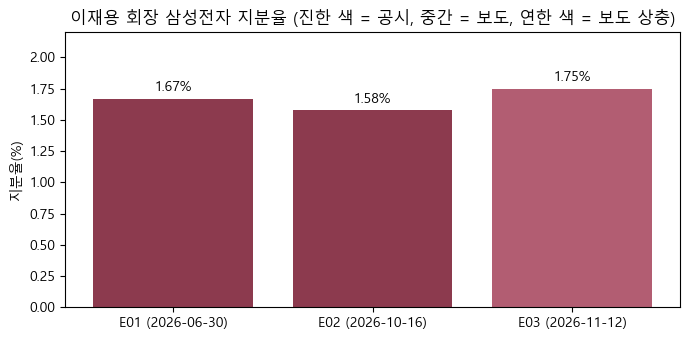

                                          항목     값  상태                                                비고
evidence_id                                                                                             
E01                    이재용 보통주 지분율(반기보고서 기말)  1.67  공시                          보통주 기준. 이전 보도 값 1.47와 다름
E02          이재용 지분율(기준일 전 마지막 임원·주요주주 소유보고)  1.58  공시  보통주+우선주 합산 기준. 보고 수량 105,219,053주, 증감 7,667,100주
E03                    홍라희 지분 증여 완료 후 예정 지분율  1.75  보도                                                  
주의: 항목마다 비율 기준(보통주 / 보통주+우선주 합산)이 다를 수 있어 막대 사이 차이를 변화폭으로 읽지 않는다.


In [7]:
stake = evidence.set_index('evidence_id').loc[['E01','E02','E03'], ['항목','값','기준일','상태','비고']]
stake['구분'] = [f'{eid} ({d})' for eid, d in zip(stake.index, stake['기준일'])]
color_map = {'공시': '#8c3a4e', '보도': '#b25d72', '보도 상충': '#d9a5b2'}

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(stake['구분'], stake['값'], color=[color_map.get(s, '#cccccc') for s in stake['상태']])
ax.bar_label(bars, fmt='%.2f%%', padding=3)
ax.set_ylim(0, 2.2)
ax.set_ylabel('지분율(%)')
ax.set_title('이재용 회장 삼성전자 지분율 (진한 색 = 공시, 중간 = 보도, 연한 색 = 보도 상충)')
plt.tight_layout(); plt.show()

print(stake[['항목', '값', '상태', '비고']].to_string())
print('주의: 항목마다 비율 기준(보통주 / 보통주+우선주 합산)이 다를 수 있어 막대 사이 차이를 변화폭으로 읽지 않는다.')

**해석**
- 지분은 시장에 팔리지 않고 가족 안에서 이동했다. 지배구조 변화와 시장 매도 물량은 없다.
- 실제 지배 경로는 "이재용 → 삼성물산 → 삼성생명 → 삼성전자"다. 경로별 지분율은 DART로 확인해야 한다.
- 보험업법 개정(E06)은 미확인이다. 통과되면 삼성생명의 삼성전자 지분 매각 압력이 생긴다. 1번(거시·정책)과 함께 추적한다.
- 3번(수급)에 넘길 사항: 오너 일가 지분 이동은 장외·증여라 시장 매도 물량이 아니다.

## 5. 영역 B. 경영진 역량
대리지표: 시장 기대 대비 실적, 사업부별 성과 편차, 대표 체제 안정성.

In [8]:
ev = evidence.set_index('evidence_id')['값']
achieve = ev['E07'] / ev['E08'] * 100
print(f'3분기 영업이익 컨센서스 달성률: {achieve:.1f}%')
print(f'비메모리 추정 영업손익: {ev["E09"]:+.1f}조원')
print(f'최근 3년 대표 체제 변경: {int(ev["E10"])}회')

3분기 영업이익 컨센서스 달성률: 99.3%
비메모리 추정 영업손익: -4.0조원
최근 3년 대표 체제 변경: 1회


**해석**
- 컨센서스를 소폭 밑돌았지만 분기 영업이익 100조 원을 넘었다. HBM4가 중심인 메모리 실행력은 실적으로 확인된다.
- 비메모리는 적자로 추정된다. 이 부문 전략은 아직 성과 근거가 없다.
- 실적 숫자 자체의 해석은 2번(산업·사업모델)이 맡는다. 5번은 "경영진이 약속한 전략을 실행했는가"만 본다.

## 6. 영역 C. 이해상충·주주환원
점검 과제: 임직원 보상용 자사주가 소각 효과를 얼마나 상쇄하는가.

보상용 자사주 매입액 / 소각 금액 = 1.03배
2026년 주주환원 의결 하단: 90조원


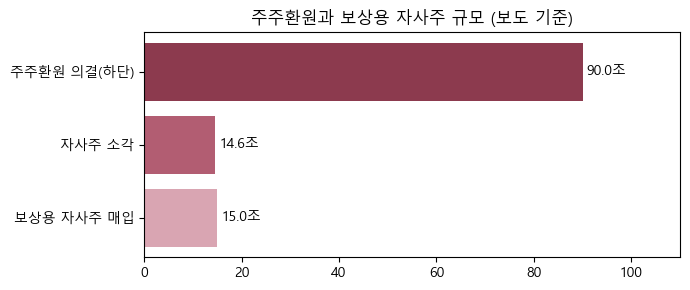

In [9]:
offset_ratio = ev['E13'] / ev['E12']
print(f'보상용 자사주 매입액 / 소각 금액 = {offset_ratio:.2f}배')
print(f'2026년 주주환원 의결 하단: {ev["E11"]:.0f}조원')

fig, ax = plt.subplots(figsize=(7, 3))
items = ['주주환원 의결(하단)', '자사주 소각', '보상용 자사주 매입']
vals = [ev['E11'], ev['E12'], ev['E13']]
bars = ax.barh(items, vals, color=['#8c3a4e', '#b25d72', '#d9a5b2'])
ax.bar_label(bars, fmt='%.1f조', padding=3)
ax.set_xlim(0, 110)
ax.invert_yaxis()
ax.set_title('주주환원과 보상용 자사주 규모 (보도 기준)')
plt.tight_layout(); plt.show()

**해석**
- 환원 규모는 크고 소각도 이행됐다. 경영진의 약속 이행 측면에서는 긍정 근거다.
- 보상용 매입액이 소각액과 비슷하다. 보상분은 시간이 지나면 시장에 풀리므로 소각 효과를 일부 상쇄한다.
- 두 금액은 시점과 집계 방식이 다르다. 비율은 "확인이 필요하다"는 신호로만 쓴다.

## 7. 영역 D·E. 이사회 감시와 법적·평판 리스크

In [10]:
board = evidence[evidence['area'].isin(['D','E'])][['evidence_id','항목','값','상태','rcept_no','비고']]
board

,evidence_id,항목,값,상태,rcept_no,비고
15,E14,이사회 의장이 사외이사인가(1=예),1.0,공시,20260814003699,의장: 신제윤(독립이사)
16,E15,실질 지배자(이재용) 등기이사 여부(1=등기),0.0,공시,20260814003699,등기임원 8명 명단 기준
17,E16,사외이사 비율,62.5,공시,20260814003699,등기임원 8명 중 사외(독립)이사 5명
18,E17,경영진 관련 재판 진행 중(1=진행 중),0.0,보도,,
19,E18,최근 1년 노조 총파업 선언(1=있음),1.0,보도,,


**해석**
- 의장과 대표가 분리돼 있고 의장은 사외이사다.
- 실질 지배자가 미등기라 결정 권한과 법적 책임이 어긋난다.
- 사법 리스크는 2025년 7월 무죄 확정으로 해소됐다.
- 노사 분쟁은 최근 1년 안에 있었다. 이익 연동 성과급의 비용 영향은 2번에 넘긴다.

## 8. 규칙 판정
LLM이 아니라 파이썬 함수가 판정한다(수업 `ch04_제어문`, `ch05_함수`).

### 값이 없거나 매체마다 다를 때
- `미확인`이거나 값이 비어 있으면 `자료 없음`이다.
- `보도 상충`이면 `값`과 `대안값`을 모두 넣어 판정한다(민감도 점검).
  - 두 결과가 같으면 그 신호를 쓴다. 어느 수치가 맞아도 결론이 같기 때문이다.
  - 결과가 다르면 `자료 없음`이다. 원문 확인 전에는 판정할 수 없다.
  - 대안값이 없으면 점검할 수 없으므로 `자료 없음`이다.
- 어떤 경우였는지는 `비고` 열에 남긴다.

### 자사주 소각 이행률 (초안)
- 계획(E19, 보도) 대비 상반기 실제 소각 수량(E20, 공시)의 비율이다.
- 기준값 95%는 **팀 합의 전 초안**이다. 계획이 "약 8,700만 주"로 발표돼 100%를 요구하면 반올림 차이만으로 주의가 된다.
- 기존 claim 번호(G01~G12)를 유지하려고 이 규칙은 목록 맨 뒤(G13)에 둔다.

In [11]:
from itertools import product

BUYBACK_EXEC_MIN = 0.95   # 소각 이행률 기준. 팀 합의 전 초안

def candidates(eid):
    """판정에 넣을 후보 값 목록. 판정할 수 없으면 None."""
    row = evidence.set_index('evidence_id').loc[eid]
    if row['상태'] == '미확인' or pd.isna(row['값']):
        return None
    if row['상태'] == '보도 상충':
        if pd.isna(row['대안값']):
            return None
        return [row['값'], row['대안값']]
    return [row['값']]

def rule(name, area, eids, judge, reason):
    cands = [candidates(e) for e in eids]
    conflict = [e for e in eids if evidence.set_index('evidence_id').loc[e, '상태'] == '보도 상충']
    if any(c is None for c in cands):
        signal = '자료 없음'
        note = f"상충 값 대조 불가({', '.join(conflict)})" if conflict else ''
    else:
        signals = {judge(*combo) for combo in product(*cands)}   # 후보 값의 모든 조합으로 판정
        signal = signals.pop() if len(signals) == 1 else '자료 없음'
        if not conflict:
            note = ''
        elif signal == '자료 없음':
            note = f"상충 값에 따라 신호가 갈림({', '.join(conflict)})"
        else:
            note = f"상충 값 모두 같은 신호({', '.join(conflict)})"
    return {'점검': name, 'area': area, 'signal': signal, 'evidence_ids': eids,
            '판정 기준': reason, '비고': note}

RULES = [
    rule('오너 지분 시장 매도', 'A', ['E04'],
         lambda x: '긍정' if x == 1 else '주의', '가족 간 이전이면 긍정, 시장 매도면 주의'),
    rule('상속세 부담 해소', 'A', ['E05'],
         lambda x: '긍정' if x == 1 else '주의', '분납 종료면 긍정'),
    rule('보험업법 개정 위험', 'A', ['E06'],
         lambda x: '주의' if x == 1 else '중립', '통과 시 지배 경로 약화'),
    rule('실적 기대 충족', 'B', ['E07', 'E08'],
         lambda a, c: '긍정' if a / c >= 0.97 else '주의', '컨센서스 97% 이상이면 긍정'),
    rule('사업부 성과 편차', 'B', ['E09'],
         lambda x: '주의' if x < 0 else '중립', '적자 부문이 있으면 주의'),
    rule('대표 체제 안정성', 'B', ['E10'],
         lambda n: '주의' if n >= 2 else '긍정', '3년 내 2회 이상 교체면 주의'),
    rule('보상용 자사주의 소각 상쇄', 'C', ['E12', 'E13'],
         lambda r, c: '주의' if c / r >= 0.5 else '중립', '보상용 매입이 소각의 50% 이상이면 주의'),
    rule('의장·대표 분리', 'D', ['E14'],
         lambda x: '긍정' if x == 1 else '주의', '의장이 사외이사면 긍정'),
    rule('실질 지배자 등기 여부', 'D', ['E15'],
         lambda x: '중립' if x == 1 else '주의', '미등기면 책임 소재 주의'),
    rule('사외이사 과반', 'D', ['E16'],
         lambda x: '긍정' if x > 50 else '주의', '과반이면 긍정'),
    rule('경영진 재판 리스크', 'E', ['E17'],
         lambda x: '주의' if x == 1 else '긍정', '진행 중이면 주의'),
    rule('노사 분쟁', 'E', ['E18'],
         lambda x: '주의' if x == 1 else '중립', '최근 1년 파업 선언이면 주의'),
    # claim 번호를 유지하려고 새 규칙은 맨 뒤에 둔다
    rule('자사주 소각 계획 이행률', 'C', ['E20', 'E19'],
         lambda done, plan: '긍정' if done / plan >= BUYBACK_EXEC_MIN else '주의',
         f'계획 대비 소각 {BUYBACK_EXEC_MIN:.0%} 이상이면 긍정(초안)'),
]
result = pd.DataFrame(RULES)
_ev = evidence.set_index('evidence_id')['값']
if pd.notna(_ev['E20']):
    print(f"자사주 소각 이행률: {_ev['E20'] / _ev['E19']:.2%} "
          f"(소각 {_ev['E20']:,.0f}주 / 계획 {_ev['E19']:,.0f}주, 기준 {BUYBACK_EXEC_MIN:.0%} 이상 긍정, 초안)")
result[['area','점검','signal','판정 기준','비고']]

자사주 소각 이행률: 99.96% (소각 86,962,775주 / 계획 87,000,000주, 기준 95% 이상 긍정, 초안)


,area,점검,signal,판정 기준,비고
0,A,오너 지분 시장 매도,긍정,"가족 간 이전이면 긍정, 시장 매도면 주의",
1,A,상속세 부담 해소,긍정,분납 종료면 긍정,
2,A,보험업법 개정 위험,자료 없음,통과 시 지배 경로 약화,
3,B,실적 기대 충족,긍정,컨센서스 97% 이상이면 긍정,
4,B,사업부 성과 편차,주의,적자 부문이 있으면 주의,
5,B,대표 체제 안정성,긍정,3년 내 2회 이상 교체면 주의,
6,C,보상용 자사주의 소각 상쇄,주의,보상용 매입이 소각의 50% 이상이면 주의,상충 값 모두 같은 신호(E12)
7,D,의장·대표 분리,긍정,의장이 사외이사면 긍정,
8,D,실질 지배자 등기 여부,주의,미등기면 책임 소재 주의,
9,D,사외이사 과반,긍정,과반이면 긍정,


In [12]:
summary = result.pivot_table(index='area', columns='signal', values='점검', aggfunc='count', fill_value=0)
summary

signal,긍정,자료 없음,주의
area,,,
A,2,1,0
B,2,0,1
C,1,0,1
D,2,0,1
E,1,0,1


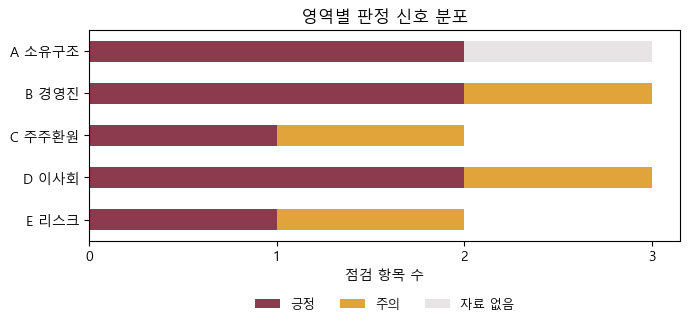

In [13]:
order = ['긍정', '중립', '주의', '자료 없음']
color = {'긍정': '#8c3a4e', '중립': '#bfb5b8', '주의': '#e0a43b', '자료 없음': '#e8e4e5'}
summary = summary.reindex(columns=[c for c in order if c in summary.columns])

ax = summary.plot(kind='barh', stacked=True, figsize=(7, 3.5),
                  color=[color[c] for c in summary.columns])
ax.set_yticklabels(['A 소유구조', 'B 경영진', 'C 주주환원', 'D 이사회', 'E 리스크'])
ax.invert_yaxis()
ax.set_xlabel('점검 항목 수')
ax.set_title('영역별 판정 신호 분포')
ax.set_ylabel('')
ax.xaxis.get_major_locator().set_params(integer=True)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=4, fontsize=9, frameon=False)
plt.tight_layout(); plt.show()

> 합계 점수는 만들지 않는다. 항목별 가중치 근거가 없어 점수가 거짓 정밀도가 되기 때문이다.

## 9. 오케스트레이터 전달용 AgentMemo
기획서 09장의 필수 항목(주장·근거·가정·반대조건·자료 완결성·미해결 과제)을 채운다.

In [14]:
# 데이터 모드는 수집 방식이 아니라 근거 표의 실제 상태로 적는다
n_disclosed = int((evidence['상태'] == '공시').sum())
if n_disclosed == 0:
    data_mode = '보도 기준'
elif n_disclosed == len(evidence):
    data_mode = 'DART'
else:
    data_mode = f'DART 일부 반영 (공시 {n_disclosed}/{len(evidence)}건)'

REASON = {'미확인': 'NO_DATA', '보도 상충': 'CONFLICT'}
ev_idx = evidence.set_index('evidence_id')
unresolved = evidence[evidence['상태'].isin(REASON)]
report_only = evidence[evidence['상태'] == '보도']   # 출처는 있으나 rcept_no가 없는 근거

def rcept_nos(eids):
    return sorted({ev_idx.loc[e, 'rcept_no'] for e in eids if ev_idx.loc[e, 'rcept_no']})

memo = {
    'agent': 'R-governance',
    'scope': '삼성전자 지배구조·경영진',
    'as_of': AS_OF,
    'data_mode': data_mode,
    'claims': [
        {'claim_id': f'G{i+1:02d}', 'text': r['점검'], 'area': r['area'],
         'signal': r['signal'], 'evidence_ids': r['evidence_ids'],
         'rcept_no': rcept_nos(r['evidence_ids']),
         **({'note': r['비고']} if r['비고'] else {})}
        for i, r in result.iterrows()
    ],
    'assumptions': ['보험업법 개정안이 기준일까지 통과되지 않았다'],
    'counter_conditions': [
        '등기이사 복귀 안건이 주총에 오르면 G09는 중립으로 바뀐다',
        '보상용 자사주 중 상당량이 소각으로 전환되면 G07은 중립으로 바뀐다',
    ],
    'handoff': [
        {'to': '3번 수급', 'item': '오너 일가 지분 이동은 장외·증여로 시장 매도 물량이 아님'},
        {'to': '2번 사업모델', 'item': '비메모리 적자와 이익 연동 성과급의 비용 영향'},
        {'to': '1번 거시·정책', 'item': '보험업법 개정 진행 단계 추적'},
    ],
    'completeness': 'complete' if data_mode == 'DART' and unresolved.empty else 'partial',
    'unresolved': [{'evidence_id': r['evidence_id'], 'item': r['항목'], 'reason': REASON[r['상태']]}
                   for _, r in unresolved.iterrows()],
    'report_only_evidence': report_only['evidence_id'].tolist(),
    'disclaimer': '투자 권유가 아니며 rcept_no가 없는 근거는 보도 기준이라 DART 원문 대조가 필요함',
}

out_path = 'agent_memo_governance_삼성전자.json'
with open(out_path, 'w', encoding='utf-8') as f:
    json.dump(memo, f, ensure_ascii=False, indent=2)
print('저장:', out_path, '| data_mode:', data_mode, '| completeness:', memo['completeness'])
print(json.dumps(memo['unresolved'], ensure_ascii=False, indent=2))

저장: agent_memo_governance_삼성전자.json | data_mode: DART 일부 반영 (공시 6/20건) | completeness: partial
[
  {
    "evidence_id": "E06",
    "item": "보험업법 개정(삼성생명법) 국회 통과 여부",
    "reason": "NO_DATA"
  },
  {
    "evidence_id": "E12",
    "item": "자사주 소각 공시 금액",
    "reason": "CONFLICT"
  }
]


## 10. 한계와 다음 단계

### 한계
- 공시로 확인한 근거는 일부다(E01·E02·E14·E15·E16·E20). 나머지는 언론 보도 기준이고 `rcept_no`가 없다.
- E01(반기보고서, 보통주 기준)과 E02(소유보고, 보통주+우선주 합산 기준)는 비율 기준이 달라 바로 비교하지 않는다.
- E01의 이전 보도 값(9월 공시 인용)은 DART 반기 값과 다르다. 해당 9월 공시 원문은 아직 찾지 못했다.
- 소각 계획 수량(E19)은 사업보고서를 인용한 보도다. 사업보고서 본문은 정형 API에 없어 원문 대조가 남았다.
- 판정 기준값(97%, 50%, 95% 등)은 팀 합의 전의 초안이다.

### 다음 단계
1. 판정 기준값을 팀과 합의한다.
2. 보도 기준 근거(`report_only_evidence`)를 공시 원문으로 하나씩 바꾼다. 특히 E12(소각 금액, 보도 상충)와 E19.
3. 사업보고서의 임원·이사회 섹션을 RAG로 검색해 근거 문장을 붙인다(수업 `07_LLM/ch9_12`).